## Module 2: FSHD Clinical Trial Project 

By: Layla Ragland

## Project Goal:

Facioscapulohumeral muscular dystrophy (or FSHD) is a genetic muscular disorder that involves progressive, often assymetrical weakening of the face, shoulders, arms and eventually other large muscle groups. FSHD is one of the most common forms of musclur dystropgy, and as such, ought to have more progress made in therapies for the treatment or prevention of such a condition. Using natural history data from a data set described below, we are aiming to identify if a new drug will be able to reduce FSHD from the starting point. However, markers of clinical progression can vary. In this analysis, we are attempting to answer two problems. Firstly, does the clinical severity score reflect changes that occur in muscle fat fraction over time? Secondly, does the clinical severity score or fat fraction give a better marker for clinical trial usage? This would allow researchers to examine the biomarker that correlates most strongly to improved sympotms for patients. 

## Disease Background: 

**Prevalence & incidence**

Incidence is around 1 in 14,286 births in the world, but this incidence is considered conservative, with a real number maybe closer to 1 in 7500.  

Global Prevelance is thought to be in a range of 1 in 8000 to 12000, but this number is very complex to verify with any high level of certianity. 

Sources:
https://www.umassmed.edu/wellstone/overview/fshdfacts

https://biologyinsights.com/fshd-prevalence-how-common-is-this-condition/#google_vignette

**Symptoms**

Symptoms intially begin most often with diffucitty raising arms above shoulder level. Then, issues with foot drop, scapular fization and facial weakness also occur. Over time, the condition leads to the progressive atrophying of all skeletal muscles. Usually, this atrophying is asymmetric as it progresses. 

Source:
https://www.umassmed.edu/wellstone/overview/fshdfacts/

**Diagnosis**

Diagnosis can occur via a couple different avenues presently. Some diagnosis occur via prenatal genetic testing, while others don't occur until symptoms arise in teenage or twenties, possibly even later. Because the condition is passed genetically, the children of families with known carriers are more likely to be watched for symtomps earlier in life. 

Source:
https://www.umassmed.edu/wellstone/overview/fshdfacts/


**Standard of care treatments & reimbursement**

Standard of caree includes help with eveeryday taks, as well as treatments to manage symotmps. These include working with physical therapists, orthopedic therapy or surgeries, as well as other occupational therapies. These can be covered in varying capacities by various insurance forms. Unfornutaly, no drug exists that is currernly approved and verified by the FDA to assist with this drug. 
Pateitns with this condition will visit doctors for most of thier life, often to continue to monitior disease progession. This can mean work with surgeons, cardiac doctors, audiologists, pulmonary doctors, general care providers and many others. 
While these visits are typically covered by insurances, the frequency and kind of visit could still impose a financial burden on families impacted by FSHD. 

Source:
https://www.fshdsociety.org/living-with-fshd/managing-fshd/clinical-care/

**Disease progression & prognosis**

The disease tends to progress slowly, while the severity of progression may vary. Most individuals will have a normal expectancy due to this. The progression usually occurs in the following manner: wekaness in the face, shoulder and upper arms, then involving other large muscle groups, including abdomen or legs, and in severe cases, hearing, visison or respirtory systems. 

Source:
https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy

**Biological mechanisms**

At the cellular level, FSHD can be traced down to a highly toxic amount of expression of the DUX4 gene due to a lack of suffieceient genetic 'silencers'. This DUX4 gene is a necessary gene for very early human development, but beyond that point, expression causes apoptosis of cells, gradually causing the loss of muscle fibers. Increased DUX4 precense also means higher suceptibility to chronic inflammation, oxidative stress, and hinderance of repair mechanisms. This causes the decline of muscle structures. 

Sources:
https://www.nature.com/articles/s42003-024-06325-z

https://biologyinsights.com/what-is-dux4-and-its-role-in-muscular-dystrophy/

**Clinical Trials & Next-gen therapies**

Some therapies include a Antisense oligonucleotide therapy where DUX4 mRNA are boudn before they can be translated into protein. These ASO molcules recognize a unique sequence of DUX4. Another strategy would try to enhance epigenetic silencing pathways that already exist. 

Source:
https://biologyinsights.com/what-is-dux4-and-its-role-in-muscular-dystrophy

## Data Set:

The FSHD dataset analyzed  in this project stems from a study published in Human Molecular Genetics. The study invovled 34 patients with FSHD, who underwent various functional testing, MRIs, DNA analuysis and biopsies. The study was designed for an initial visit, and two follow ups at approximately 1 year and 2 years. The data collected from those tests was as follows:

Subjects had lower extremeity MRIs, focused on their tibialis anterior (TA) which where used to determine local fat fractions. However, these ranged significnatly, but the majority had a fat fraction less than 10%. This method involved a method of pixel percentage of fat, and yieleded the fat image and water-image files. 

The TA segmentation was dual approached using AI to segment the MRI images, and then vetting from a team of engineerings to produce the 3D label of the TA and then yield it's volume. 

The image singals are given as STIR scores, a value without a unit. Or, as a fat perecentage, as well as fat along a length. 

Now, as to the published dataset, it includes subject id, sex, age, and genetic info. Alongside that, it includes the DUX4 amounts, the baseline fat fractions and STIR values, as well as the results of the physical examination. Then, these values as they repeated. 


Source:
Wong, Chao-Jen, et al. "Regional and bilaterial MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression", https://doi.org/10.1093/hmg/ddae007, Human Molecular Genetics, 2024, Volume 33. 


## MRI Data Analysis Methdology:

For the data set, there is a line that measures fat fraction at each visit. This was done via MRI data that was analysed via segmentation and a computer program that gave the fat fraction as a percentage of pixels of fat. This information is NOT needed to understand the later interpolation, but is a necessary methodology to understand for the sake of replication.

The methodology of the MRI analysis will first be explained here, and then replicated using the model code provided in the coursework. 

Step 1: To begin, the data was loaded into the file and placed into a pandas data frame for easier manipulation.

Step 2: Each sample is loaded with it's individual fat slice files, and presents the pixel information.

Step 3: The TA mask is able to identify the muscle alone by not counting locations where pixel values are zero. At non-zero pixel values, the fat fraction is calculated as a fraction of fat over total pixels.

Step 4: The output is given as 'heat maps' of the TA and it's fat content. These summary statistics are presented in bar graphs, data tables and provide means, medians and standard deviations for them.

Step 5: Then, over the course of multiple visits, line graphs are created to show changes in trends of percents of muscle fat. This graph is an example for the sake of this explanation, and is not needed to understand the analysis done later. 

Each code block is labeled by the step it corresponds to. 

In [2]:
# Step 1

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("FSHD_TA_MRI_data_0020_TP1_TP2")
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


In [8]:
# Step 2:

row = manifest[manifest["timepoint"] == "TP1"].iloc[3]  # representative mid-muscle slice

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())


Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


In [13]:
# Step 3:

denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(
    fat,
    denominator,
    out=np.zeros_like(fat, dtype=float),
    where=valid_pixels
) * 100

# Keep the whole supplied image region for the first analysis.
fat_fraction_full = fat_fraction.copy()

# Then apply the TA mask for the muscle-specific analysis.
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region — mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region — minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region — maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only — mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only — minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only — maximum: {np.max(muscle_values):.1f}%")


Whole supplied image region — mean: 50.0%
Whole supplied image region — minimum: 0.0%
Whole supplied image region — maximum: 100.0%

TA muscle only — mean: 27.9%
TA muscle only — minimum: 0.0%
TA muscle only — maximum: 88.1%


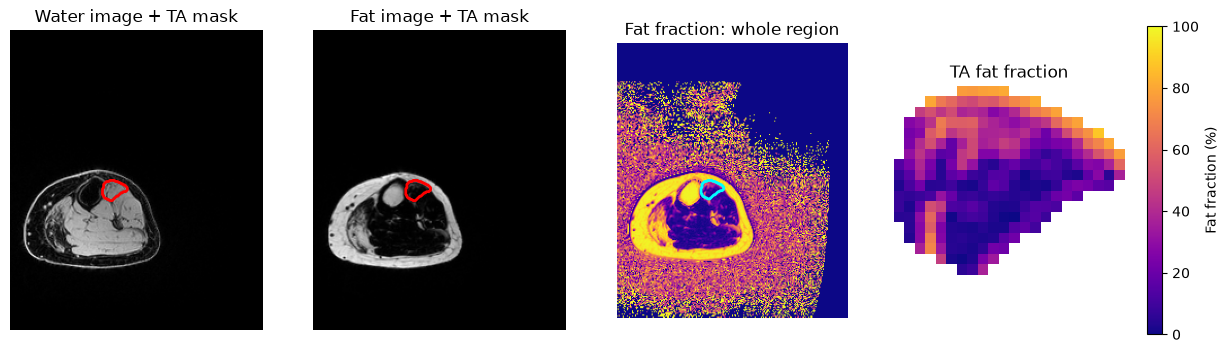

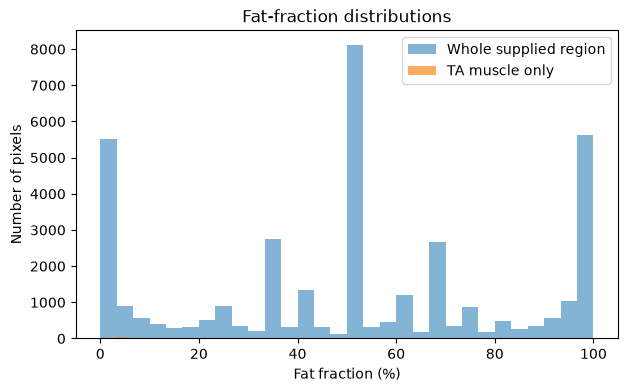

In [17]:
# Step 4

# Find the bounding box of the TA mask
y_pixels, x_pixels = np.where(mask)

y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1

# Crop the TA-specific fat-fraction map
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Water image with TA mask outline
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

# Fat image with TA mask outline
axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

# Fat fraction for the whole supplied image region
whole_image = axes[2].imshow(
    fat_fraction_full,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

# Zoomed-in fat fraction for the TA only
ta_image = axes[3].imshow(
    fat_fraction_TA,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[3].set_title("TA fat fraction")

for ax in axes:
    ax.axis("off")

# Both fat-fraction plots use the same 0–100% scale
fig.colorbar(
    ta_image,
    ax=axes[2:],
    fraction=0.046,
    pad=0.04,
    label="Fat fraction (%)"
)

plt.show()



# Then, for bar graphs and summary statistics: 

plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=30, alpha=0.55, label="Whole supplied region")
plt.hist(muscle_values, bins=30, alpha=0.65, label="TA muscle only")
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distributions")
plt.legend()
plt.show()


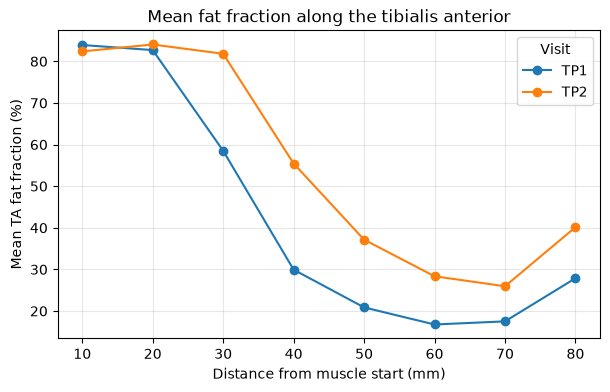

In [20]:
# Step 5

def calculate_fat_fraction(water, fat, mask):
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(
        fat,
        denominator,
        out=np.zeros_like(fat, dtype=float),
        where=denominator > 0
    ) * 100
    result[~mask] = np.nan
    return result

analysis_timepoint = "TP1"  # analyze one visit at a time
analysis_manifest = manifest[manifest["timepoint"] == analysis_timepoint]
results = []

for _, row in analysis_manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)

    results.append({
        "subject": row["subject"],
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "percent_along_muscle": row["percent_along_muscle"],
        "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
    })

results_df = pd.DataFrame(results)
results_df

def summarize_visit(timepoint):
    visit_results = []
    visit_manifest = manifest[manifest["timepoint"] == timepoint]

    for _, row in visit_manifest.iterrows():
        water = np.load(DATA_DIR / row["water_file"])
        fat = np.load(DATA_DIR / row["fat_file"])
        mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
        ff = calculate_fat_fraction(water, fat, mask)

        visit_results.append({
            "timepoint": timepoint,
            "slice_id": row["slice_id"],
            "percent_along_muscle": row["percent_along_muscle"],
            "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
            "mean_fat_fraction_percent": np.nanmean(ff),
        })

    return pd.DataFrame(visit_results)

profiles_df = pd.concat(
    [summarize_visit("TP1"), summarize_visit("TP2")],
    ignore_index=True
)

plt.figure(figsize=(7, 4))
for timepoint, group in profiles_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(
        group["percent_along_muscle"],
        group["mean_fat_fraction_percent"],
        marker="o",
        label=timepoint
    )
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()


## Interpolation Analysis:

Because the value points are not at exact same timepoints, interpolation allowed us to create a common analysis point for the data as a whole. The varaibles used for the interpolation are time, the clinical severity score and fat fraction. In order to ensure the use of a common time point for all the mathamtics, the minimum values were found for use in the interpretations to avoid the practice of extrapolation, which would involve projecting data, which is considered more risky. By instead working from the minimum value to each individual's real value, it provides data that is within the known change of the variable. Baseline to T1 were found via a linear interpretation whereas Baseline to T2 was found with a quadratic due to the increase in data points.

Interpolation is not a definition of an exact or new value, but it does provide a valuable estimate. By knowing how the graph is changing, it allows us to predict what that value must have been along the line or curve, as explained above.


Below, I have given the code and outcomes. The comments at the top contain the explanation of each section, what it does, and what any outputs may suggest.

In [22]:
# First, the proper packages must be imported
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


# Then, the csv file is read into a pandas DataFrame
df = pd.read_csv("Module2_FSHD_Dataset.csv")
print(df.shape)
df

(34, 46)


,subject_id,sex,age_baseline,d4z4,dux4_signature_baseline_R,dux4_signature_baseline_L,lag_months_baseline,lag_months_y1,lag_months_y2,ff_baseline_R,...,wr_10_y2,ascend_4_baseline,ascend_4_y1,ascend_4_y2,descend_4_baseline,descend_4_y1,descend_4_y2,clinical_severity_score_baseline,clinical_severity_score_y1,clinical_severity_score_y2
0,1-0019,M,47.06,4,0.060426,0.052982,0,11.74,22.78,5.977253,...,2.52,1.89,2.13,1.63,1.76,1.84,1.64,2,3.0,3.0
1,1-0020,F,24.28,4,0.029324,0.085611,0,16.80,NaN,10.825636,...,NaN,2.15,2.50,NaN,1.89,2.07,NaN,4,6.0,NaN
2,1-0021,M,36.42,6,0.056946,0.264634,0,12.20,23.51,3.346368,...,2.65,1.40,1.60,1.76,1.52,1.40,1.39,0,0.0,1.0
3,1-0022,F,59.43,2,0.877067,0.217580,0,13.35,24.82,5.476659,...,4.44,1.97,2.15,1.97,1.87,2.25,2.27,3,3.0,2.0
4,1-0023,M,63.92,5,2.694204,2.876636,0,11.97,24.39,26.596680,...,3.59,2.32,2.26,2.20,2.00,2.13,2.15,4,4.0,6.0
5,1-0024,M,36.94,7,0.038643,0.066797,0,11.97,22.13,8.298934,...,2.40,1.82,1.97,1.89,1.77,1.89,1.72,3,3.0,2.0
6,1-0025,F,61.67,5,0.116768,0.456562,0,12.69,25.38,9.510767,...,6.71,3.25,2.85,2.95,3.19,2.89,2.81,6,7.0,6.0
7,1-0026,F,22.49,7,0.269544,2.024060,0,12.43,23.84,11.947834,...,5.35,1.93,2.34,2.33,1.88,1.82,2.18,6,6.0,5.0
8,1-0028,M,39.64,5,0.419893,0.171500,0,12.00,24.49,5.450935,...,3.76,2.46,2.66,1.83,2.39,2.58,1.53,3,3.0,6.0
9,1-0029,F,37.00,8,0.029904,0.097613,0,11.74,23.84,3.634287,...,4.08,1.85,1.69,1.84,2.21,1.75,1.72,5,5.0,5.0


In [31]:
# Check for missing visits -- not every subject has a Year 1 and/or Year 2 visit
# For the purpose of this analysis, we will only use patients who have a visit in at least year 1. The number of subjects used for the analysis with
# year 2 is slightly less because some did not attend a Year 2 visit
print("Subjects:", len(df))
print("Have a Year 1 visit:", df['lag_months_y1'].notna().sum())
print("Have a Year 2 visit:", df['lag_months_y2'].notna().sum())

T1 = df['lag_months_y1'].min()   # earliest Year-1 visit across all subjects
T2 = df['lag_months_y2'].min()   # earliest Year-2 visit across all subjects
print(f"T1 = {T1:.2f} months")
print(f"T2 = {T2:.2f} months")


Subjects: 34
Have a Year 1 visit: 32
Have a Year 2 visit: 27
T1 = 11.15 months
T2 = 22.13 months


In [39]:
# This is the interpolation loop! 

# First, create a empty list that will store dictionary result combos for each subject's information
results = []

for idx, row in df.iterrows():
    # This brings a row up and identifies it via subject_id
    subject_id = row['subject_id']

    # Then, the subject_id is used to find that corresponding row in the data frame
    row = df.loc[df['subject_id'] == subject_id].iloc[0]

    #From the row, we extract the time values of the visits and the corresponding ff_R values, and put them in an array
    lag_months = np.array([row['lag_months_baseline'], row['lag_months_y1'], row['lag_months_y2']])
    ff_values = np.array([row['ff_baseline_R'], row['ff_y1_R'], row['ff_y2_R']])

    # Print the extracted arrays for proof
    print("lag_months:", lag_months)
    print("ff_values: ", ff_values)

    # As long as the subject has at least baseline and Year 1 visits (no NaNs), we can compute their linear estimate at T1.
    # If not, fill in the value with NaN
    # The equation is built to construct an estimate value through the (time, ff value) as a coordinate pair
    if not np.isnan(lag_months[:2]).any() and not np.isnan(ff_values[:2]).any() and lag_months[0] != lag_months[1]:
        estimate_T1_linear = float(interp1d(lag_months[:2], ff_values[:2], kind='linear')(T1))
    else:
        estimate_T1_linear = np.nan

    # Similar to above, we check if the subject has all three visits (no NaNs) and compute their quadratic estimate at T2. If not, use NaN instead.
    if not np.isnan(lag_months).any() and not np.isnan(ff_values).any() and len(set(lag_months)) == 3:
        estimate_T2_quadratic = float(interp1d(lag_months, ff_values, kind='quadratic')(T2))
    else:
        estimate_T2_quadratic = np.nan

    # Add the estimates the results as a dictionary entry
    # Estimate_T1 is the fat fraction value estimated at time T1, and estimate_T2 is the fat fraction value estimated at time T2.
    results.append({'subject_id': subject_id, 'estimate_T1_linear': estimate_T1_linear, 'estimate_T2_quadratic': estimate_T2_quadratic})

    pass

# Turn `results` into a DataFrame and inspect it
results_df = pd.DataFrame(results)
results_df

# Below, the data frame results are printed, and you can see the varying values for interpolation displayed.

lag_months: [ 0.   11.74 22.78]
ff_values:  [5.97725324 6.78554252 6.69765696]
lag_months: [ 0.  16.8  nan]
ff_values:  [10.82563624         nan         nan]
lag_months: [ 0.   12.2  23.51]
ff_values:  [3.3463683  5.08999266 4.26840037]
lag_months: [ 0.   13.35 24.82]
ff_values:  [5.47665879 6.84161261 6.42961785]
lag_months: [ 0.   11.97 24.39]
ff_values:  [26.59668028         nan         nan]
lag_months: [ 0.   11.97 22.13]
ff_values:  [8.29893425 8.03390145 8.4139742 ]
lag_months: [ 0.   12.69 25.38]
ff_values:  [ 9.51076672 11.7339246  11.54428273]
lag_months: [ 0.   12.43 23.84]
ff_values:  [11.94783375 11.29846349 12.17018738]
lag_months: [ 0.   12.   24.49]
ff_values:  [5.45093492 5.13967387 5.64354472]
lag_months: [ 0.   11.74 23.84]
ff_values:  [3.63428667 5.19567914 4.63860184]
lag_months: [ 0.   12.66 24.26]
ff_values:  [16.47025347 16.56793803 20.2741757 ]
lag_months: [ 0.  24.3 24.3]
ff_values:  [12.69095838  8.39155391         nan]
lag_months: [ 0.  12.2  nan]
ff_values: 

,subject_id,estimate_T1_linear,estimate_T2_quadratic
0,1-0019,6.744922,6.725603
1,1-0020,NaN,NaN
2,1-0021,4.939927,4.494294
3,1-0022,6.616676,6.657714
4,1-0023,NaN,NaN
5,1-0024,8.052057,8.413974
6,1-0025,11.464132,11.822690
7,1-0026,11.365333,11.950039
8,1-0028,5.161722,5.483636
9,1-0029,5.117211,4.850758


Mean estimated fat fraction at T1 (linear): 20.80
Mean estimated fat fraction at T2 (quadratic): 18.72
Standard deviation of estimated fat fraction at T1 (linear): 23.62
Standard deviation of estimated fat fraction at T2 (quadratic): 22.54


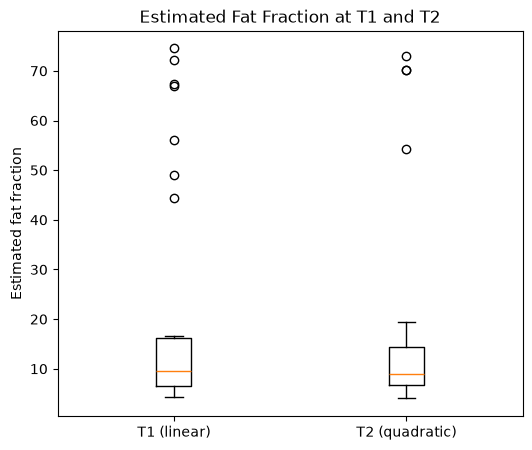

In [46]:
# This is a boxplot of the estimated fat fraction at T1 (linear) and T2 (quadratic)
fig, ax = plt.subplots(figsize=(6, 5))

# the following lines drops NaN values from the estimated fat fraction columns before plotting the boxplot
data = [results_df['estimate_T1_linear'].dropna(),
        results_df['estimate_T2_quadratic'].dropna()]
ax.boxplot(data, tick_labels=['T1 (linear)', 'T2 (quadratic)'])
ax.set_ylabel('Estimated fat fraction')
ax.set_title('Estimated Fat Fraction at T1 and T2')

# Displaying the means and standard deviations for easy comparison
mean_T1 = results_df['estimate_T1_linear'].mean()
mean_T2 = results_df['estimate_T2_quadratic'].mean()
standard_dev_T1 = results_df['estimate_T1_linear'].std()
standard_dev_T2 = results_df['estimate_T2_quadratic'].std()
print(f"Mean estimated fat fraction at T1 (linear): {mean_T1:.2f}")
print(f"Mean estimated fat fraction at T2 (quadratic): {mean_T2:.2f}")
print(f"Standard deviation of estimated fat fraction at T1 (linear): {standard_dev_T1:.2f}")
print(f"Standard deviation of estimated fat fraction at T2 (quadratic): {standard_dev_T2:.2f}")

plt.show()

# GRAPH A:
# Conclusion from this graph: the overlap in standard deviations makes it difficult to distinguish significant differences between T1 and T2 estimates.

In [52]:
# Exact same process as above, but for the clinical severity score

estimates = []

for idx, row in df.iterrows():
    subject_id = row['subject_id']

    row = df.loc[df['subject_id'] == subject_id].iloc[0]

    lag_months = np.array([row['lag_months_baseline'], row['lag_months_y1'], row['lag_months_y2']])
    clinical_severity_score_values = np.array([row['clinical_severity_score_baseline'], row['clinical_severity_score_y1'], row['clinical_severity_score_y2']])

    print("lag_months:", lag_months)
    print("clinical_severity_score_values: ", clinical_severity_score_values)

    if not np.isnan(lag_months[:2]).any() and not np.isnan(clinical_severity_score_values[:2]).any() and lag_months[0] != lag_months[1]:
        estimate_T1_linear = float(interp1d(lag_months[:2], clinical_severity_score_values[:2], kind='linear')(T1))
    else:
        estimate_T1_linear = np.nan

    if not np.isnan(lag_months).any() and not np.isnan(clinical_severity_score_values).any() and len(set(lag_months)) == 3:
        estimate_T2_quadratic = float(interp1d(lag_months, clinical_severity_score_values, kind='quadratic')(T2))
    else:
        estimate_T2_quadratic = np.nan
    
    estimates.append({'subject_id': subject_id, 'estimate_T1_linear': estimate_T1_linear, 'estimate_T2_quadratic': estimate_T2_quadratic})

    pass
    
    estimates.append({'subject_id': row['subject_id'], 'baseline': clinical_severity_score_values[0],'T1': estimate_T1_linear,'T2': estimate_T2_quadratic})

# Turn estimates into a DataFrame
estimates_df = pd.DataFrame(estimates)

lag_months: [ 0.   11.74 22.78]
clinical_severity_score_values:  [2. 3. 3.]
lag_months: [ 0.  16.8  nan]
clinical_severity_score_values:  [ 4.  6. nan]
lag_months: [ 0.   12.2  23.51]
clinical_severity_score_values:  [0. 0. 1.]
lag_months: [ 0.   13.35 24.82]
clinical_severity_score_values:  [3. 3. 2.]
lag_months: [ 0.   11.97 24.39]
clinical_severity_score_values:  [4. 4. 6.]
lag_months: [ 0.   11.97 22.13]
clinical_severity_score_values:  [3. 3. 2.]
lag_months: [ 0.   12.69 25.38]
clinical_severity_score_values:  [6. 7. 6.]
lag_months: [ 0.   12.43 23.84]
clinical_severity_score_values:  [6. 6. 5.]
lag_months: [ 0.   12.   24.49]
clinical_severity_score_values:  [3. 3. 6.]
lag_months: [ 0.   11.74 23.84]
clinical_severity_score_values:  [5. 5. 5.]
lag_months: [ 0.   12.66 24.26]
clinical_severity_score_values:  [5. 6. 3.]
lag_months: [ 0.  24.3 24.3]
clinical_severity_score_values:  [3. 3. 3.]
lag_months: [ 0.  12.2  nan]
clinical_severity_score_values:  [ 3.  2. nan]
lag_months: [ 0

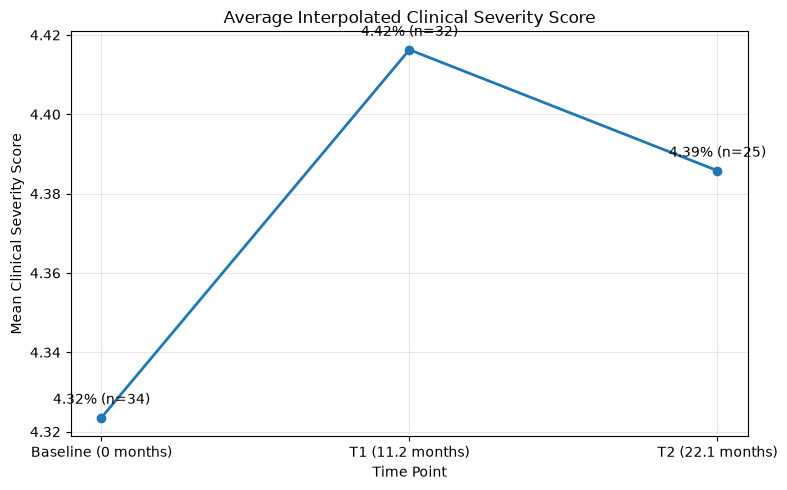

In [57]:
# Data anlysis and graphical portions now

# Calculate the average across patients at each time point
mean_ff = estimates_df[['baseline', 'T1', 'T2']].mean()
counts = estimates_df[['baseline', 'T1', 'T2']].count()

# Plot average interpolated fat fraction
labels = [
    'Baseline (0 months)',
    f'T1 ({T1:.1f} months)',
    f'T2 ({T2:.1f} months)'
]

plt.figure(figsize=(8, 5))
plt.plot(labels, mean_ff.values, marker='o', linewidth=2)

for i, (mean, n) in enumerate(zip(mean_ff.values, counts.values)):
    plt.annotate(
        f'{mean:.2f}% (n={n})',
        (i, mean),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center'
    )

plt.title('Average Interpolated Clinical Severity Score')
plt.xlabel('Time Point')
plt.ylabel('Mean Clinical Severity Score')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# GRAPH B
# Conclusion: Clinical severity score doesn't change much over time, but it does exhibit a decrease between T1 and T2.


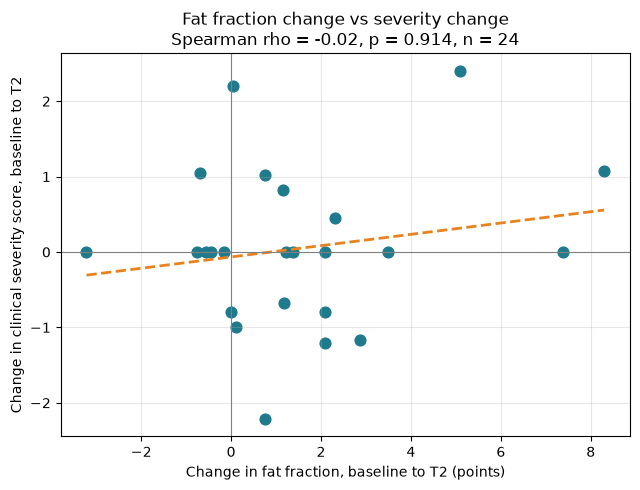

In [61]:
# The next section combines fat fraction and clinical severity score into one data frame matched on subject_id, so that the following graphs, 
# which will compare them together, are easier to produce.

# Must convert list results and estimates into workable data frame
ff = pd.DataFrame({
    'subject_id': results_df['subject_id'],
    'ff0': df['ff_baseline_R'].values,
    'ff1': results_df['estimate_T1_linear'],
    'ff2': results_df['estimate_T2_quadratic'],
})

# The second data frame 
css = (estimates_df[['subject_id', 'baseline', 'T1', 'T2']]
       .dropna(subset=['baseline'])          # keeps only the rows from your 2nd append
       .drop_duplicates('subject_id')
       .rename(columns={'baseline': 'css0', 'T1': 'css1', 'T2': 'css2'}))

# Then, the data frames are merged on subject_id to create a combined data frame
comb = ff.merge(css, on='subject_id')

# This defines the differences between baseline and T2 for both fat fraction and clinical severity score
comb['ff_change'] = comb['ff2'] - comb['ff0']       
comb['css_change'] = comb['css2'] - comb['css0']

x_months = [0, T1, T2]
tlabels = ['Baseline', f'T1\n({T1:.1f} mo)', f'T2\n({T2:.1f} mo)']

#Now, we move onto graphing these together.
d = comb.dropna(subset=['ff_change', 'css_change'])

# The spearman correlation between changes in fat fraction and clinical severity score
rho, p = spearmanr(d['ff_change'], d['css_change'])
plt.figure(figsize=(6.5, 5))
plt.scatter(d['ff_change'], d['css_change'], color="#1f7a8c", s=60)
if len(d) > 2:
    m, b = np.polyfit(d['ff_change'], d['css_change'], 1)
    xs = np.linspace(d['ff_change'].min(), d['ff_change'].max(), 50)
    plt.plot(xs, m * xs + b, color="#e8821e", lw=2, ls="--")
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("Change in fat fraction, baseline to T2 (points)")
plt.ylabel("Change in clinical severity score, baseline to T2")
plt.title(f"Fat fraction change vs severity change\nSpearman rho = {rho:.2f}, p = {p:.3f}, n = {len(d)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# GRAPH C
# Conclusion: Because Spearman rho is strongest correlation near -1 or 1, the near zero values implies minimal correlation between changes in 
# fat fraction and clinical severity score. The p value is much above the typical significance threshold, indicating that the observed correlation 
# is not statistically significant.


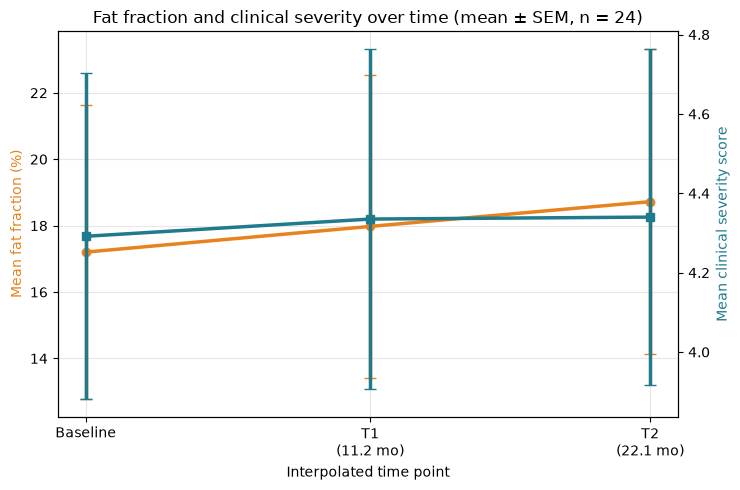

In [64]:
# Prepare the data for plotting mean fat fraction and clinical severity score over time
d = comb.dropna(subset=['ff0', 'ff1', 'ff2', 'css0', 'css1', 'css2'])
n = len(d)

# Calculate the mean and standard error of the mean for fat fraction and clinical severity score at each time point
ff_mean = d[['ff0', 'ff1', 'ff2']].mean().values
ff_sem = d[['ff0', 'ff1', 'ff2']].sem().values
css_mean = d[['css0', 'css1', 'css2']].mean().values
css_sem = d[['css0', 'css1', 'css2']].sem().values

# Plot mean fat fraction and clinical severity score over time
fig, ax1 = plt.subplots(figsize=(7.5, 5))
ax1.errorbar(x_months, ff_mean, yerr=ff_sem, color="#e8821e", marker='o', lw=2.5, capsize=4)
ax1.set_ylabel("Mean fat fraction (%)", color="#e8821e")
ax2 = ax1.twinx()
ax2.errorbar(x_months, css_mean, yerr=css_sem, color="#1f7a8c", marker='s', lw=2.5, capsize=4)
ax2.set_ylabel("Mean clinical severity score", color="#1f7a8c")
ax1.set_xticks(x_months)
ax1.set_xticklabels(tlabels)
ax1.set_xlabel("Interpolated time point")
ax1.set_title(f"Fat fraction and clinical severity over time (mean ± SEM, n = {n})")
ax1.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# GRAPH D
# Conclusion: The plot shows the mean fat fraction and clinical severity score over time, with error bars representing the standard error of the mean. 
# This allows for a visual assessment of trends and variability in the data across the different time points. But, because of the massive overlap in the 
# standard deviation bars, there is not clear statistically significant difference between the time points or different measures. 


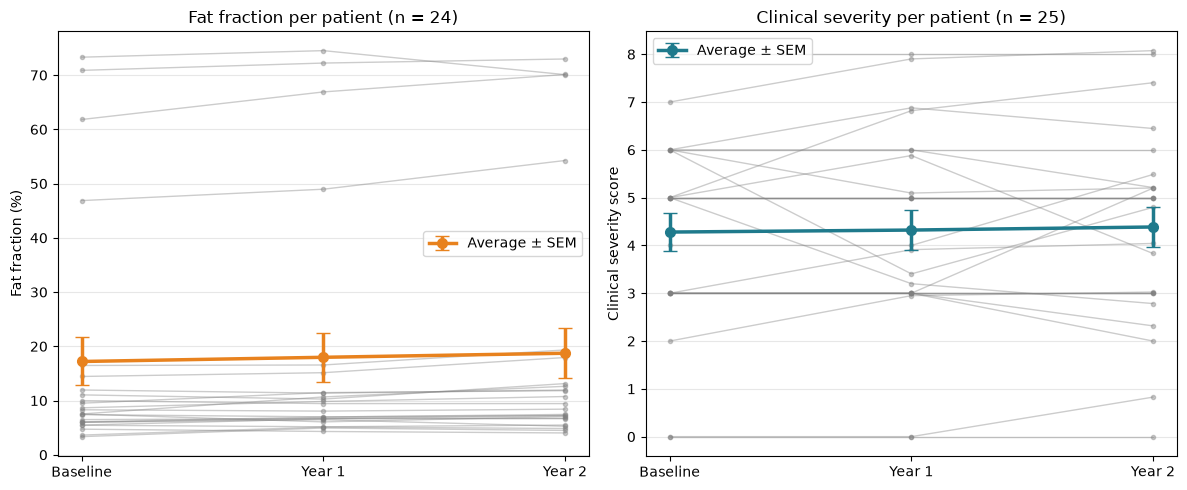

In [66]:
# Function to plot individual patient lines with average and SEM over time
def patient_lines(ax, data, cols, title, ylabel, line_color, tlabels=('Baseline', 'Year 1', 'Year 2')):
    dd = data.dropna(subset=cols)
    vals = dd[cols].to_numpy()
    pos = [0, 1, 2]
    means = vals.mean(axis=0)
    sems = dd[cols].sem().values

    # Individual patient lines
    ax.plot(pos, vals.T, color="gray", alpha=0.4, marker='o', ms=3, lw=1)

    # Average line with error bars 
    ax.errorbar(pos, means, yerr=sems, color=line_color, marker='o', ms=7,
                lw=2.5, capsize=5, label="Average ± SEM", zorder=3)

    ax.set_xticks(pos)
    ax.set_xticklabels(tlabels)
    ax.set_title(f"{title} (n = {len(dd)})")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3, axis='y')
    ax.legend()

fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 5))
patient_lines(axL, comb, ['ff0', 'ff1', 'ff2'], "Fat fraction per patient", "Fat fraction (%)", "#e8821e")
patient_lines(axR, comb, ['css0', 'css1', 'css2'], "Clinical severity per patient", "Clinical severity score", "#1f7a8c")


fig.tight_layout()
plt.show()

# GRAPH E
# Conclusion: The plots show individual trajectory, and then the average trend is shown with error bars. Unfornuately, there is no ability to 
# distinguish a statistically significant difference between time points due to overlapping error bars.

## Conclusions:

Remember, the question we sought to answer with this analysis are as follows: Does the clinical severity score reflect changes that occur in muscle fat fraction over time? Secondly, does the clinical severity score or fat fraction give a better marker for clinical trial usage? 

For the first question, it would appear that clinical severity score is inconclusive as to if it reflects changes well. As demonstrated on graph E, the clinical severity score in in line with the changes in fat fraction, but those also appeared to be neglible as a whole. In graph B, clinical severity score took a peak between the baseline and T2, which would suggest that it is not adequately represetnign the degenerative nature of the disease as a whole. However, due to the small sample size of this data set, removing the clinical severity score as an ineffective metric would be unbacked by suffiecent research and could negatively affect the field as a whole. In future, the Clinical severity score should recieve more study. 

Then, the question between whether clinical severity score or fat fraction as a better marker is also largely inconclusive. Neither, in the scope of this analysis, contained a statiscally significant difference between them that would imply that one is a better choice than the other. Picking one of these over the other will require more research, and for now, the best option for the field would likely be continuing to balance between these clinical standards so that patients from different areas can have access to the most effecient clinical perception metrics for them. 

As verification for this study, it makes sense that the perception of clinical severity scores may not be effective over time, and that the fat fraction data is largely inconclusive due to the sample size overall. As for verification, a study in the European Journal of Neurology found that clinical scores for FSHD only seem to accurately represent patients with incredibly severe cases, and otherwise, do not reflect the disease progression in it's more common slow form. For the fat fraction data though, studies like one from Nuerology, show it as a medium to high effective data point for analysing progress. However, the number of data points collected in that study were much higher than this data set as a whole, so this unclear data does not detract from the conclusion made in that article, it just cannot enhance it. 

For the purpose of the clinical trial as a whole, it provides a need for more research. Another thing that should be considered is patient experience as a whole, for it is well known that patients do not always feel accuratly reflected by the clinical severity score or fat fraction data. 

Sources:


Teeselink, Sjan et al. "The Facioscapulohumeral Muscular Dystrophy Rasch‐Built Overall Disability Scale (FSHD‐RODS): Longitudinal Assessment of a Disease‐Specific Patient Reported Outcome", https://pmc.ncbi.nlm.nih.gov/articles/PMC12334892/, European Journal of Nuerology, August 9, 2025. 


Mellion, Michelle, et al. "Quantitative Muscle Analysis in FSHD Using Whole-Body Fat-Referenced MRI", https://www.neurology.org/doi/10.1212/wnl.0000000000200757, Nuerology, August 30, 2022. 


## Limitations and Future Work:

As with any study or analysis, there are limitations. This data set was very small, and the number of completed visits was even a little smaller than that. Differences between 'good and bad days' for patients are difficult to accomodate for, and differences in provider teams or evaluators can change some perceptions of functionality. The fat fraction scores are limited by the frequency they were taken. 

Overall, if more time and resources were present, then increasing the size of the data set would be significant. Also, as possibly identifed in graph A, the data set may have contained some outliers, which if removed could have clarified the results some. More time could have included an outlier analysis, as well as a further consideration of some of the other metrics included in the data set, including the physical movement tests.

## AI Usage Statement:

Claude Sonnet 5.5 was used for debugging purposes and to help generate some of the additional graphs.
AI did not write any of the writings, nor the central code bodies.

## GitHub Repository Link:

https://github.com/LayR451/BME2315_Module2

## References:

Reynolds, Petr. "What is DUX4 and it's role in Muscular Dystrophy?", https://biologyinsights.com/what-is-dux4-and-its-role-in-muscular- dystrophy, Biology Insights, July 25, 2025.

Schatzl, Teresa, et al. "Meta-aanylsis towards FSHD reveals misregulation of nueromuscular junction, nuclear envelope, and spliceosome", https://www.nature.com/articles/s42003-024-06325-z, Communications Biology, 25 May, 2024.

"Facioscapulohumeral Muscular Dystrophy (FSHD)", https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy, Muscular Dystrophy Association, April 2026.

'FSHD Clinical Care", https://www.fshdsociety.org/living-with-fshd/managing-fshd/clinical-care/, FSHD Society.

Sander-Webb, Jessica. "FSHD Prevelance: How Common is this Condition?", https://biologyinsights.com/fshd-prevalence-how-common-is-this-condition/#google_vignette, Biology Insights, October 13, 2026.

"Facts and Statistic about FSHD", https://www.umassmed.edu/wellstone/overview/fshdfacts, UMass Chan Medical School, Wellness Center. 

Wong, Chao-Jen, et al. "Regional and bilaterial MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression", https://doi.org/10.1093/hmg/ddae007, Human Molecular Genetics, 2024, Volume 33. 

Teeselink, Sjan et al. "The Facioscapulohumeral Muscular Dystrophy Rasch‐Built Overall Disability Scale (FSHD‐RODS): Longitudinal Assessment of a Disease‐Specific Patient Reported Outcome", https://pmc.ncbi.nlm.nih.gov/articles/PMC12334892/, European Journal of Nuerology, August 9, 2025. 


Mellion, Michelle, et al. "Quantitative Muscle Analysis in FSHD Using Whole-Body Fat-Referenced MRI", https://www.neurology.org/doi/10.1212/wnl.0000000000200757, Nuerology, August 30, 2022. 


## NOTES FROM YOUR TEAM: 

Just as a note, I completed this assignment alone. I was given an extension to Sunday (10/24)

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*